In [18]:
#!/usr/bin/env python3
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import colormaps
import pandas as pd

try:
    import mplhep as hep
    hep.style.use("ATLAS")
except:
    pass


In [43]:

labelsDict = {'mS' : lambda x: r'$m_S$ =' + f' {x:1.0f} GeV' if x is not None else r'$m_S$ [GeV]',
        'm1' : lambda x: r'$m_{\chi_1}$ =' + f' {x:1.2f} GeV' if x is not None else r'$m_{\chi_1}$ [GeV]',
        'dm' : lambda x: r'$\Delta m$ =' + f' {x:1.2f} GeV' if x is not None else r'$\Delta m$ [GeV]',
        'tau' : lambda x: r'$c \tau$ =' + f' {x*3e8:1.0f} m' if x is not None else r'$c \tau$ [m]',
    #   'm0' : lambda x: r'$m_{\chi_0}$ =' + f' {x:1.2f} [GeV]',
    #   'm2' : lambda x: r'$m_{\chi_2}$ =' + f' {x:1.2f} [GeV]'
        'brchi12bbchi0' : r'BR($\chi_1 \to b b \chi_0$)',
        'brchi12tautauchi0' : r'BR($\chi_1 \to \tau \tau \chi_0$)',
        'brchi22bbchi0' : r'BR($\chi_2 \to b b \chi_0$)',
        'brchi22tautauchi0' : r'BR($\chi_2 \to \tau \tau \chi_0$)',
        'brchi22tautauchi1' : r'BR($\chi_2 \to \tau \tau \chi_1$)',
        'brs2zz' : r'BR($S \to Z Z$)',
        'brs2hh' : r'BR($S \to h h$)',
        'brs2ww' : r'BR($S \to W W$)',
        'brs2tt' : r'BR($S \to t t$)',
        'brs2chi1chi2' : r'BR($S \to \chi_1 \chi_2$)',
        'brs2chi0chi2' : r'BR($S \to \chi_0 \chi_2$)',
        'brs2bb' : r'BR($S \to b b$)',
        'brs2gg' : r'BR($S \to g g$)',
        'brs2tautau' : r'BR($S \to \tau \tau$)',
        'brs2chi0chi1' : r'BR($S \to \chi_0 \chi_1$)'
        }

### Get B2TF recast data

In [5]:
b2tf_DF = pd.read_csv('../b2tf_effs_13TeV_new.csv')
b2tf_DF['dm'] = (b2tf_DF['m1']-b2tf_DF['m0']).round(0)
b2tf_DF['ctau'] = (b2tf_DF['tau']*2.99e8).round(0)
b2tf_DF['ctau_full'] = (b2tf_DF['tau']*2.99e8)
print(len(b2tf_DF))



138


In [9]:
print(b2tf_DF.columns)

Index(['m1', 'm0', 'ms', 'tau', 'brchi12bbchi0', 'brchi12tautauchi0',
       'brchi22bbchi0', 'brchi22tautauchi0', 'brchi22tautauchi1', 'brs2zz',
       'brs2hh', 'brs2ww', 'brs2tt', 'brs2chi1chi2', 'brs2chi0chi2', 'brs2bb',
       'brs2gg', 'brs2tautau', 'brs2chi0chi1', 'm2', 'lambdauv', 'chxx10',
       'ychi20', 'ychi21', 'sina', 'xsec_pb', 'eff', 'efferror', 'filename',
       'brchi12ggchi0', 'brchi22ggchi0', 'dm', 'ctau', 'ctau_full'],
      dtype='str')


## Plot BR(S -> XX)

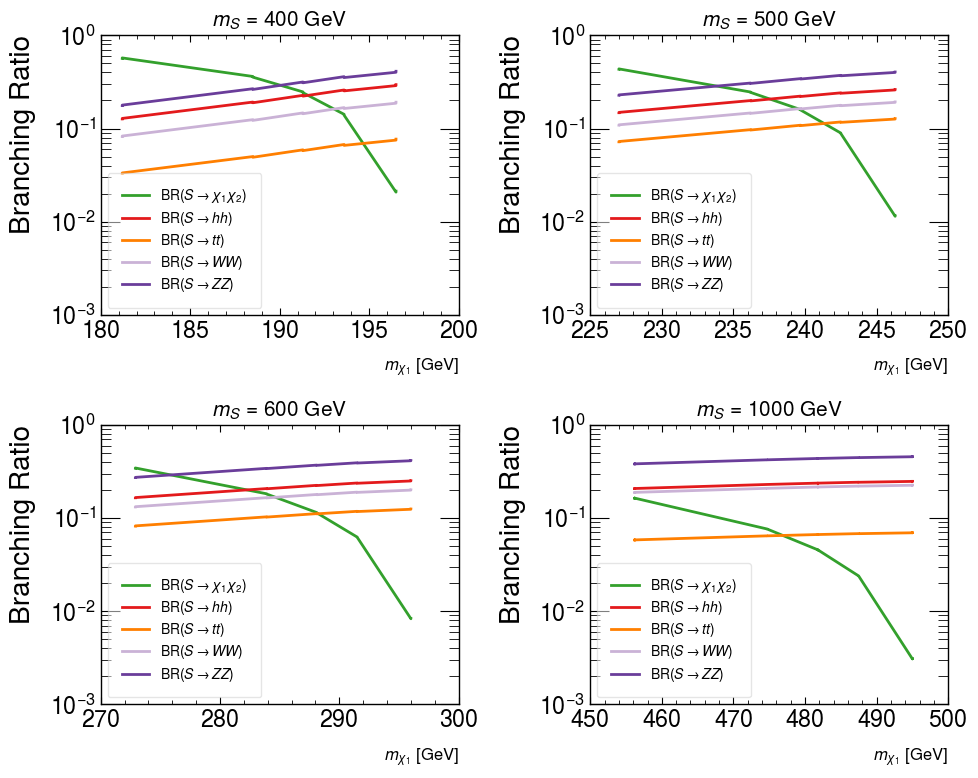

In [52]:
mSValues = sorted(b2tf_DF['ms'].unique())[::2]
ncolumns = 2
nrows = len(mSValues) // ncolumns + (len(mSValues) % ncolumns > 0)


fig,axarr = plt.subplots(nrows=nrows, ncols=ncolumns, figsize=(5*ncolumns, 4*nrows))
iax = 0
axes = axarr.flatten() if nrows > 1 else [axarr]


colorDict = {}
cmap = list(colormaps["Paired"].colors)
linestyles = ['solid','dashed','dotted','dashdot']
brList = sorted([col for col in b2tf_DF.columns if col.startswith('brs2')])
for br in brList:
    colorDict[br] = cmap.pop(0)
first = True
for ms in mSValues:
    df_filter = b2tf_DF[b2tf_DF['ms'] == ms].sort_values(by='m1')
    ls = 'solid'
    ax = axes[iax]
    iax += 1
    for br in brList:
        x = df_filter['m1'].values
        y = df_filter[br].values
        if max(y) < 5e-2:
            continue
        label = labelsDict.get(br,br)
        
        ax.plot(x,y,c=colorDict[br], label=label,linestyle=ls)
    ax.set_ylim(1e-3,1)
    ax.set_title(labelsDict['mS'](ms),fontsize=15)
    ax.set_xlabel(labelsDict['m1'](None),fontsize=12)
    ax.set_ylabel('Branching Ratio')
    ax.legend(fontsize=10,frameon=True,framealpha=0.5,facecolor='white',loc='lower left')
    ax.set_yscale('log')
plt.tight_layout()
plt.show()